# 30 K-Nearest Neighbors (KNN) Programs for Data Science
A comprehensive guide covering KNN classification, regression, distance metrics, hyperparameter tuning, scaling effects, high-dimensional challenges, and real-world pipelines using `scikit-learn`.


### 1. Basic KNN Classification

In [1]:
from sklearn.datasets import make_blobs
from sklearn.neighbors import KNeighborsClassifier

X, y = make_blobs(n_samples=100, centers=2, random_state=42)
knn = KNeighborsClassifier(n_neighbors=3).fit(X, y)

print("Model Training Score:", knn.score(X, y))

Model Training Score: 1.0


### 2. Finding Nearest Neighbors and Distances

In [2]:
from sklearn.datasets import make_blobs
from sklearn.neighbors import NearestNeighbors

X, _ = make_blobs(n_samples=10, centers=2, random_state=42)
nbrs = NearestNeighbors(n_neighbors=3, algorithm='ball_tree').fit(X)

distances, indices = nbrs.kneighbors(X[:1])
print("Distances to 3 Nearest Neighbors:", distances)
print("Indices of Nearest Neighbors:", indices)

Distances to 3 Nearest Neighbors: [[0.         1.12932761 1.17891599]]
Indices of Nearest Neighbors: [[0 3 5]]


### 3. Impact of K Value on Overfitting and Underfitting

In [3]:
from sklearn.datasets import make_moons
from sklearn.neighbors import KNeighborsClassifier

X, y = make_moons(n_samples=100, noise=0.3, random_state=42)

for k in [1, 5, 20, 50]:
    clf = KNeighborsClassifier(n_neighbors=k).fit(X, y)
    print(f"K={k:2d} | Accuracy: {clf.score(X, y):.2f}")

K= 1 | Accuracy: 1.00
K= 5 | Accuracy: 0.94
K=20 | Accuracy: 0.90
K=50 | Accuracy: 0.84


### 4. Visualizing KNN Decision Boundaries

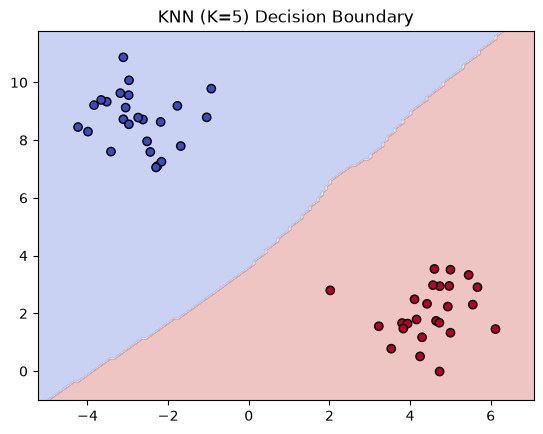

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.neighbors import KNeighborsClassifier

X, y = make_blobs(n_samples=50, centers=2, random_state=42)
clf = KNeighborsClassifier(n_neighbors=5).fit(X, y)

x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1), np.arange(y_min, y_max, 0.1))

Z = clf.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', edgecolors='k')
plt.title("KNN (K=5) Decision Boundary")
plt.show()

### 5. Distance Weighting (Uniform vs. Distance)

In [5]:
from sklearn.datasets import make_classification
from sklearn.neighbors import KNeighborsClassifier

X, y = make_classification(n_samples=200, n_features=2, n_redundant=0, random_state=42)

clf_uniform = KNeighborsClassifier(n_neighbors=5, weights='uniform').fit(X, y)
clf_distance = KNeighborsClassifier(n_neighbors=5, weights='distance').fit(X, y)

print("Uniform Weights Accuracy:", clf_uniform.score(X, y))
print("Distance Weights Accuracy:", clf_distance.score(X, y))

Uniform Weights Accuracy: 0.91
Distance Weights Accuracy: 1.0


### 6. KNN with Manhattan Distance (L1 Metric)

In [6]:
from sklearn.datasets import load_iris
from sklearn.neighbors import KNeighborsClassifier

X, y = load_iris(return_X_y=True)
clf = KNeighborsClassifier(n_neighbors=5, metric='manhattan').fit(X, y)

print("Manhattan Metric Accuracy:", clf.score(X, y))

Manhattan Metric Accuracy: 0.9666666666666667


### 7. KNN with Minkowski Distance (Custom p-value)

In [7]:
from sklearn.datasets import load_iris
from sklearn.neighbors import KNeighborsClassifier

X, y = load_iris(return_X_y=True)
# p=3 corresponds to Minkowski distance of order 3
clf = KNeighborsClassifier(n_neighbors=5, metric='minkowski', p=3).fit(X, y)

print("Minkowski (p=3) Accuracy:", clf.score(X, y))

Minkowski (p=3) Accuracy: 0.9666666666666667


### 8. KNN with Cosine Distance Metric

In [8]:
from sklearn.datasets import make_classification
from sklearn.neighbors import KNeighborsClassifier

X, y = make_classification(n_samples=150, n_features=4, random_state=42)
clf = KNeighborsClassifier(n_neighbors=5, metric='cosine').fit(X, y)

print("Cosine Metric Accuracy:", clf.score(X, y))

Cosine Metric Accuracy: 0.9466666666666667


### 9. Comparing Neighbor Search Algorithms (KD-Tree vs. Ball-Tree vs. Brute)

In [9]:
import time
from sklearn.datasets import make_classification
from sklearn.neighbors import KNeighborsClassifier

X, y = make_classification(n_samples=5000, n_features=10, random_state=42)

for algo in ['brute', 'kd_tree', 'ball_tree']:
    start = time.time()
    clf = KNeighborsClassifier(n_neighbors=15, algorithm=algo).fit(X, y)
    clf.predict(X)
    print(f"Algorithm: {algo:10s} | Time: {time.time() - start:.4f} sec")

Algorithm: brute      | Time: 0.0354 sec
Algorithm: kd_tree    | Time: 0.1258 sec
Algorithm: ball_tree  | Time: 0.1689 sec


### 10. Custom Distance Metric in KNN

In [10]:
import numpy as np
from sklearn.datasets import make_blobs
from sklearn.neighbors import KNeighborsClassifier

def custom_chebyshev(x, y):
    return np.max(np.abs(x - y))

X, y = make_blobs(n_samples=100, centers=2, random_state=42)
clf = KNeighborsClassifier(n_neighbors=3, metric=custom_chebyshev).fit(X, y)

print("Custom Chebyshev Distance Accuracy:", clf.score(X, y))

Custom Chebyshev Distance Accuracy: 1.0


### 11. Impact of Feature Scaling on KNN

In [11]:
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

X, y = load_wine(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Unscaled
clf_unscaled = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)
print("Unscaled Test Accuracy:", clf_unscaled.score(X_test, y_test))

# Scaled
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

clf_scaled = KNeighborsClassifier(n_neighbors=5).fit(X_train_scaled, y_train)
print("Scaled Test Accuracy:  ", clf_scaled.score(X_test_scaled, y_test))

Unscaled Test Accuracy: 0.7407407407407407
Scaled Test Accuracy:   0.9629629629629629


### 12. Finding Optimal K using Elbow Method

In [12]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

X, y = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

error_rates = []
for k in range(1, 21):
    knn = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
    pred_k = knn.predict(X_test)
    error_rates.append(1 - knn.score(X_test, y_test))

print("Lowest Error Rate at K =", error_rates.index(min(error_rates)) + 1)

Lowest Error Rate at K = 9


### 13. Predicting Class Probabilities with KNN

In [13]:
from sklearn.datasets import load_iris
from sklearn.neighbors import KNeighborsClassifier

X, y = load_iris(return_X_y=True)
clf = KNeighborsClassifier(n_neighbors=5).fit(X, y)

probs = clf.predict_proba(X[:3])
print("Predicted Class Probabilities:\n", probs)

Predicted Class Probabilities:
 [[1. 0. 0.]
 [1. 0. 0.]
 [1. 0. 0.]]


### 14. Cross-Validation Evaluation

In [14]:
from sklearn.datasets import load_digits
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier

X, y = load_digits(return_X_y=True)
pipeline = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))

scores = cross_val_score(pipeline, X, y, cv=5)
print("5-Fold Cross Validation Accuracy:", scores.mean())

5-Fold Cross Validation Accuracy: 0.9443624264933457


### 15. Grid Search CV for Hyperparameter Tuning

In [15]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier

X, y = load_breast_cancer(return_X_y=True)

pipe = Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsClassifier())])
param_grid = {
    'knn__n_neighbors': [3, 5, 7, 9, 11],
    'knn__weights': ['uniform', 'distance'],
    'knn__metric': ['euclidean', 'manhattan']
}

grid = GridSearchCV(pipe, param_grid, cv=5).fit(X, y)
print("Best Parameters:", grid.best_params_)
print("Best Cross-Validation Score:", grid.best_score_)

Best Parameters: {'knn__metric': 'euclidean', 'knn__n_neighbors': 7, 'knn__weights': 'uniform'}
Best Cross-Validation Score: 0.9701288619779538


### 16. Randomized Search for Fast KNN Tuning

In [16]:
from sklearn.datasets import load_wine
from sklearn.model_selection import RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier

X, y = load_wine(return_X_y=True)

pipe = Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsClassifier())])
param_dist = {
    'knn__n_neighbors': range(1, 20),
    'knn__weights': ['uniform', 'distance'],
    'knn__p': [1, 2, 3]
}

search = RandomizedSearchCV(pipe, param_dist, n_iter=10, cv=3, random_state=42).fit(X, y)
print("Best Parameters:", search.best_params_)

Best Parameters: {'knn__weights': 'distance', 'knn__p': 2, 'knn__n_neighbors': 12}


### 17. Building Scikit-Learn Pipelines with KNN

In [17]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier

X, y = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

pipeline = Pipeline([
    ('scaler', MinMaxScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=7))
])

pipeline.fit(X_train, y_train)
print("Pipeline Test Accuracy:", pipeline.score(X_test, y_test))

Pipeline Test Accuracy: 0.9649122807017544


### 18. Basic KNN Regression

In [18]:
import numpy as np
from sklearn.neighbors import KNeighborsRegressor

X = np.sort(5 * np.random.rand(40, 1), axis=0)
y = np.sin(X).ravel()

knr = KNeighborsRegressor(n_neighbors=5, weights='uniform').fit(X, y)
print("KNN Regressor Score (R^2):", knr.score(X, y))

KNN Regressor Score (R^2): 0.99225329006903


### 19. KNN Regression with Distance Weighting

In [19]:
import numpy as np
from sklearn.neighbors import KNeighborsRegressor

X = np.sort(5 * np.random.rand(50, 1), axis=0)
y = np.sin(X).ravel() + np.random.normal(0, 0.1, 50)

knr = KNeighborsRegressor(n_neighbors=5, weights='distance').fit(X, y)
print("Distance-Weighted Regressor R^2 Score:", knr.score(X, y))

Distance-Weighted Regressor R^2 Score: 1.0


### 20. Multi-output KNN Regression

In [20]:
import numpy as np
from sklearn.neighbors import KNeighborsRegressor

X = np.random.rand(50, 3)
y = np.c_[np.sin(X[:, 0]), np.cos(X[:, 1])]

knr = KNeighborsRegressor(n_neighbors=3).fit(X, y)
print("Multi-output Prediction Shape:", knr.predict(X[:2]).shape)

Multi-output Prediction Shape: (2, 2)


### 21. Outlier Detection using Local Outlier Factor (LOF)

In [21]:
import numpy as np
from sklearn.neighbors import LocalOutlierFactor

X = 0.3 * np.random.randn(100, 2)
X_train = np.r_[X + 2, X - 2]
X_outliers = np.random.uniform(low=-4, high=4, size=(20, 2))
X_all = np.r_[X_train, X_outliers]

lof = LocalOutlierFactor(n_neighbors=20)
y_pred = lof.fit_predict(X_all)

print("Detected Outliers Count (-1):", np.sum(y_pred == -1))

Detected Outliers Count (-1): 24


### 22. KNN Imputer for Missing Data Handling

In [22]:
import numpy as np
from sklearn.impute import KNNImputer

X = [[1, 2, np.nan], [3, 4, 3], [np.nan, 6, 5], [8, 8, 7]]
imputer = KNNImputer(n_neighbors=2)

X_imputed = imputer.fit_transform(X)
print("Imputed Data Matrix:\n", X_imputed)

Imputed Data Matrix:
 [[1.  2.  4. ]
 [3.  4.  3. ]
 [5.5 6.  5. ]
 [8.  8.  7. ]]


### 23. Radius Neighbors Classification

In [23]:
from sklearn.datasets import make_blobs
from sklearn.neighbors import RadiusNeighborsClassifier

X, y = make_blobs(n_samples=100, centers=2, random_state=42)
clf = RadiusNeighborsClassifier(radius=1.5, outlier_label=-1).fit(X, y)

preds = clf.predict(X[:5])
print("Radius Neighbors Predictions:", preds)

Radius Neighbors Predictions: [0 1 0 1 1]


### 24. Overcoming Curse of Dimensionality with PCA + KNN

In [24]:
from sklearn.datasets import load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier

X, y = load_digits(return_X_y=True)

pipeline = make_pipeline(
    StandardScaler(),
    PCA(n_components=10),
    KNeighborsClassifier(n_neighbors=5)
)

pipeline.fit(X, y)
print("PCA (10 components) + KNN Score:", pipeline.score(X, y))

PCA (10 components) + KNN Score: 0.9632721202003339


### 25. Text Document Classification with TF-IDF + KNN

In [25]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline

corpus = [
    'Machine learning is fascinating',
    'Python programming and data analysis',
    'Deep learning models and neural networks',
    'Software engineering and web development'
]
labels = [1, 1, 1, 0]

model = make_pipeline(TfidfVectorizer(), KNeighborsClassifier(n_neighbors=2))
model.fit(corpus, labels)

print("Text Prediction:", model.predict(["Neural network model in python"]))

Text Prediction: [1]


### 26. Image Classification on Handwritten Digits Dataset

In [26]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

X, y = load_digits(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

clf = KNeighborsClassifier(n_neighbors=3).fit(X_train, y_train)
print("Digits Classification Accuracy:", clf.score(X_test, y_test))

Digits Classification Accuracy: 0.9685185185185186


### 27. Neighborhood Components Analysis (NCA) Feature Reduction

In [27]:
from sklearn.datasets import load_iris
from sklearn.neighbors import NeighborhoodComponentsAnalysis, KNeighborsClassifier
from sklearn.pipeline import make_pipeline

X, y = load_iris(return_X_y=True)

nca_pipe = make_pipeline(
    NeighborhoodComponentsAnalysis(n_components=2, random_state=42),
    KNeighborsClassifier(n_neighbors=5)
)

nca_pipe.fit(X, y)
print("NCA + KNN Accuracy:", nca_pipe.score(X, y))

NCA + KNN Accuracy: 0.98


### 28. Evaluating Classification Metrics (Precision, Recall, ROC-AUC)

In [28]:
from sklearn.datasets import make_classification
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, roc_auc_score

X, y = make_classification(n_samples=200, random_state=42)
clf = KNeighborsClassifier(n_neighbors=5).fit(X, y)

y_pred = clf.predict(X)
y_proba = clf.predict_proba(X)[:, 1]

print("Classification Report:\n", classification_report(y, y_pred))
print(f"ROC-AUC Score: {roc_auc_score(y, y_proba):.3f}")

Classification Report:
               precision    recall  f1-score   support

           0       0.88      0.87      0.88       102
           1       0.87      0.88      0.87        98

    accuracy                           0.88       200
   macro avg       0.87      0.88      0.87       200
weighted avg       0.88      0.88      0.88       200

ROC-AUC Score: 0.941


### 29. Handling Imbalanced Data using Neighborhood Cleaning

In [29]:
from sklearn.datasets import make_classification
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report

X, y = make_classification(n_samples=1000, weights=[0.9, 0.1], random_state=42)

clf = KNeighborsClassifier(n_neighbors=5, weights='distance').fit(X, y)
print("Distance Weighted KNN on Imbalanced Data:\n", classification_report(y, clf.predict(X)))

Distance Weighted KNN on Imbalanced Data:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00       897
           1       1.00      1.00      1.00       103

    accuracy                           1.00      1000
   macro avg       1.00      1.00      1.00      1000
weighted avg       1.00      1.00      1.00      1000



### 30. Persisting and Reloading a KNN Model using Joblib

In [30]:
import joblib
from sklearn.datasets import load_iris
from sklearn.neighbors import KNeighborsClassifier

X, y = load_iris(return_X_y=True)
clf = KNeighborsClassifier(n_neighbors=3).fit(X, y)

# Export model
joblib.dump(clf, 'knn_model.pkl')

# Load model
loaded_knn = joblib.load('knn_model.pkl')
print("Loaded KNN Model Accuracy:", loaded_knn.score(X, y))

Loaded KNN Model Accuracy: 0.96
